# Valuación de opciones y del convertible de Apple en Python

**Proyecto final · Productos Derivados y Administración de Riesgos Corporativos · Equipo 7 · EGADE Business School**

Complementa al notebook GARCH. Usa la misma fecha de corte (**6 de noviembre de 2026**) y los mismos parámetros del reporte en
R Markdown, para que las cifras coincidan entre entregables:

1. Datos de AAPL y volatilidad histórica.
2. Black-Scholes-Merton con dividendo para la call AAPL 345 (vence 18-dic-2026) y volatilidad implícita del precio de mercado.
3. Árbol binomial CRR americano contra Black-Scholes y su convergencia.
4. Griegas analíticas y por diferencias finitas en el árbol.
5. Escenarios de precio y volatilidad para la posición del equipo.
6. Bono convertible (bono recto + opción), validación con el caso Molson Coors y call spread.

**Fuentes:** precios diarios de Yahoo Finance (`3_reporte_reproducible/datos/aapl_yahoo.csv`); volatilidad GARCH(1,1)-t y supuestos de tasas del reporte
reproducible (`3_reporte_reproducible/resultados/resumen.json`). En Colab ambos archivos se leen directamente del repositorio de GitHub.

In [1]:
import json, os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq

REPO = "https://raw.githubusercontent.com/danielsanchez-ai/Derivados_ProyectoFinal_AAPL/main/3_reporte_reproducible/"
LOCAL = "../3_reporte_reproducible/"

def leer(rel):
    # Usa el archivo local si existe (repositorio clonado); si no, lo descarga de GitHub (Colab)
    return LOCAL + rel if os.path.exists(LOCAL + rel) else REPO + rel

precios = pd.read_csv(leer("datos/aapl_yahoo.csv"), parse_dates=["fecha"])
precios.columns = [c.replace("AAPL.", "") for c in precios.columns]
fuente = leer("resultados/resumen.json")
R = json.load(open(fuente)) if os.path.exists(fuente) else json.load(urllib.request.urlopen(fuente))

FECHA_CORTE = pd.Timestamp("2026-11-06")
precios = precios[precios["fecha"] <= FECHA_CORTE]
print("Observaciones:", len(precios), "· de", precios["fecha"].min().date(), "a", precios["fecha"].max().date())
precios.tail()

Observaciones: 1255 · de 2021-11-08 a 2026-11-06


,fecha,Open,High,Low,Close,Volume,Adjusted
1250,2026-11-02,342.670013,343.799988,335.820007,338.320007,64757700.0,338.320007
1251,2026-11-03,325.579987,334.500000,325.329987,331.899994,63160000.0,331.899994
1252,2026-11-04,341.570007,354.500000,340.989990,349.510010,89637700.0,349.510010
1253,2026-11-05,353.890015,355.380005,342.059998,344.170013,75678900.0,344.170013
1254,2026-11-06,338.730011,345.790009,338.299988,342.369995,44676300.0,342.369995


## 1. Datos y parámetros

In [2]:
S0 = float(precios["Close"].iloc[-1])                 # cierre del 6-nov-2026
K, T = 345.0, R["call"]["T"]                          # call AAPL 345, vence 18-dic-2026 (42 días)
r, q = R["call"]["r"], R["q"]                         # Treasury a 1 año y dividend yield
precio_mercado, prima_pagada = R["call"]["valor_mercado"], 13.50
sigma_garch = R["garch"]["sigma_call"]                # volatilidad GARCH promedio hasta el vencimiento

rend = np.log(precios["Adjusted"]).diff().dropna()
sigma_hist = rend.tail(252).std() * np.sqrt(252)

pd.DataFrame({"Valor": [f"US${S0:,.2f}", f"US${K:,.0f}", f"{T*365:.0f} días", f"{r:.2%}", f"{q:.2%}",
                        f"{sigma_hist:.2%}", f"{sigma_garch:.2%}", f"US${precio_mercado:.2f}"]},
             index=["Precio de AAPL", "Strike", "Plazo", "Tasa libre de riesgo", "Dividend yield",
                    "Volatilidad histórica (1 año)", "Volatilidad GARCH a vencimiento", "Precio de mercado (Investopedia)"])

,Valor
Precio de AAPL,US$342.37
Strike,US$345
Plazo,42 días
Tasa libre de riesgo,4.33%
Dividend yield,0.32%
Volatilidad histórica (1 año),24.85%
Volatilidad GARCH a vencimiento,29.53%
Precio de mercado (Investopedia),US$11.25


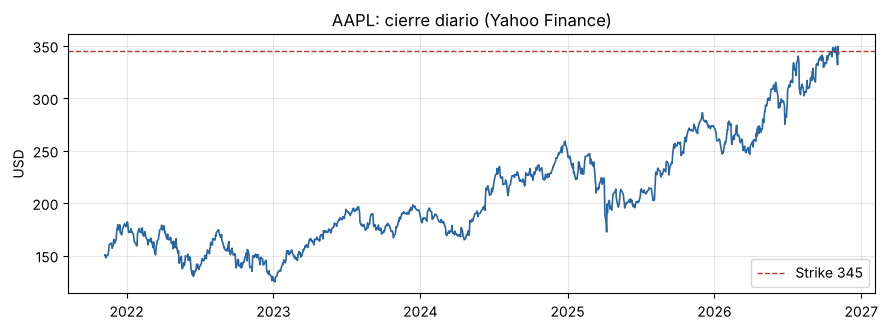

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(precios["fecha"], precios["Close"], color="#2866a5", lw=1.2)
ax.axhline(K, color="#b0392f", ls="--", lw=1, label="Strike 345")
ax.set_title("AAPL: cierre diario (Yahoo Finance)"); ax.set_ylabel("USD"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 2. Black-Scholes-Merton con dividendo y volatilidad implícita

In [4]:
def bs(S, K, r, q, s, T, tipo="call"):
    d1 = (np.log(S / K) + (r - q + s**2 / 2) * T) / (s * np.sqrt(T)); d2 = d1 - s * np.sqrt(T)
    if tipo == "call":
        return S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)

iv_bs = brentq(lambda s: bs(S0, K, r, q, s, T) - precio_mercado, 0.01, 2.0)
tabla_bs = pd.DataFrame({
    "Volatilidad": [sigma_hist, sigma_garch, iv_bs],
    "Black-Scholes": [bs(S0, K, r, q, s, T) for s in (sigma_hist, sigma_garch, iv_bs)]},
    index=["Histórica 1 año", "GARCH a vencimiento", "Implícita del precio de mercado"])
tabla_bs["Contra mercado"] = tabla_bs["Black-Scholes"] - precio_mercado
tabla_bs.style.format({"Volatilidad": "{:.2%}", "Black-Scholes": "US${:.2f}", "Contra mercado": "{:+.2f}"})

,Volatilidad,Black-Scholes,Contra mercado
Histórica 1 año,24.85%,US$11.01,-0.24
GARCH a vencimiento,29.53%,US$13.18,+1.93
Implícita del precio de mercado,25.37%,US$11.25,+0.00


**Interpretación.** Con la volatilidad que GARCH espera para la vida de la opción, Black-Scholes da más que el precio de
mercado: el mercado cobra una volatilidad implícita menor. La diferencia es una señal de volatilidad, no una ganancia asegurada.

## 3. Árbol binomial CRR americano contra Black-Scholes

In [5]:
def crr(S, K, r, q, s, T, N=500, tipo="call", americana=True):
    dt = T / N; u = np.exp(s * np.sqrt(dt)); d = 1 / u; p = (np.exp((r - q) * dt) - d) / (u - d); desc = np.exp(-r * dt)
    ST = S * u ** np.arange(N, -1, -1) * d ** np.arange(0, N + 1)
    V = np.maximum(ST - K, 0) if tipo == "call" else np.maximum(K - ST, 0)
    for i in range(N - 1, -1, -1):
        V = desc * (p * V[:-1] + (1 - p) * V[1:])
        if americana:
            Si = S * u ** np.arange(i, -1, -1) * d ** np.arange(0, i + 1)
            V = np.maximum(V, (Si - K) if tipo == "call" else (K - Si))
    return V[0]

tabla_arbol = pd.DataFrame({
    "Árbol CRR americano (500 pasos)": [crr(S0, K, r, q, s, T) for s in tabla_bs["Volatilidad"]],
    "Black-Scholes europeo": tabla_bs["Black-Scholes"]}, index=tabla_bs.index)
tabla_arbol["Diferencia (árbol − Black-Scholes)"] = tabla_arbol.iloc[:, 0] - tabla_arbol.iloc[:, 1]
print(f"Árbol con volatilidad GARCH: US${tabla_arbol.iloc[1, 0]:.2f} (reporte en R: US${R['call']['garch_valor']:.2f})")
tabla_arbol.style.format("US${:.4f}")

Árbol con volatilidad GARCH: US$13.18 (reporte en R: US$13.18)


,Árbol CRR americano (500 pasos),Black-Scholes europeo,Diferencia (árbol − Black-Scholes)
Histórica 1 año,US$11.0074,US$11.0125,US$-0.0051
GARCH a vencimiento,US$13.1796,US$13.1797,US$-0.0001
Implícita del precio de mercado,US$11.2443,US$11.2500,US$-0.0057


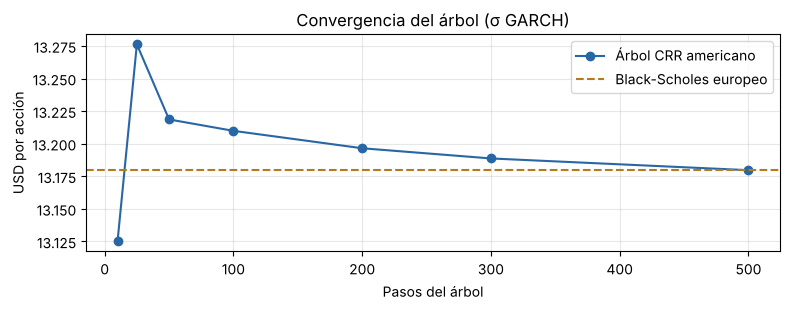

In [6]:
pasos = [10, 25, 50, 100, 200, 300, 500]
conv = [crr(S0, K, r, q, sigma_garch, T, N) for N in pasos]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(pasos, conv, "o-", color="#2866a5", label="Árbol CRR americano")
ax.axhline(bs(S0, K, r, q, sigma_garch, T), color="#b7791f", ls="--", label="Black-Scholes europeo")
ax.set_xlabel("Pasos del árbol"); ax.set_ylabel("USD por acción"); ax.set_title("Convergencia del árbol (σ GARCH)")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

**Interpretación.** El árbol converge a Black-Scholes: con un dividendo pequeño y 42 días al vencimiento no conviene ejercer
la call antes de tiempo, así que la americana y la europea valen prácticamente lo mismo.

## 4. Griegas: fórmulas de Black-Scholes contra diferencias finitas en el árbol

In [7]:
def griegas_bs(S, K, r, q, s, T):
    d1 = (np.log(S / K) + (r - q + s**2 / 2) * T) / (s * np.sqrt(T)); d2 = d1 - s * np.sqrt(T)
    return {"Delta": np.exp(-q * T) * norm.cdf(d1),
            "Gamma": np.exp(-q * T) * norm.pdf(d1) / (S * s * np.sqrt(T)),
            "Vega (por 1 pp)": S * np.exp(-q * T) * norm.pdf(d1) * np.sqrt(T) / 100,
            "Theta (por día)": (-S * np.exp(-q * T) * norm.pdf(d1) * s / (2 * np.sqrt(T)) + q * S * np.exp(-q * T) * norm.cdf(d1)
                                - r * K * np.exp(-r * T) * norm.cdf(d2)) / 365,
            "Rho (por 1 pp)": K * T * np.exp(-r * T) * norm.cdf(d2) / 100}

def griegas_arbol(S, K, r, q, s, T, N=300):
    h, ds, dt = S * 0.01, 0.01, 1 / 365
    f = lambda **k: crr(k.get("S", S), K, k.get("r", r), q, k.get("s", s), k.get("T", T), N)
    v0, vu, vd = f(), f(S=S + h), f(S=S - h)
    return {"Delta": (vu - vd) / (2 * h), "Gamma": (vu - 2 * v0 + vd) / h**2,
            "Vega (por 1 pp)": (f(s=s + ds) - f(s=s - ds)) / 2,
            "Theta (por día)": f(T=T - dt) - v0, "Rho (por 1 pp)": (f(r=r + 0.01) - f(r=r - 0.01)) / 2}

g = pd.DataFrame({"Black-Scholes (por acción)": griegas_bs(S0, K, r, q, sigma_garch, T),
                  "Árbol CRR (por acción)": griegas_arbol(S0, K, r, q, sigma_garch, T)})
g["Por contrato (×100)"] = g["Black-Scholes (por acción)"] * 100
g.style.format("{:.4f}")

,Black-Scholes (por acción),Árbol CRR (por acción),Por contrato (×100)
Delta,0.5077,0.5065,50.7720
Gamma,0.0116,0.0113,1.1625
Vega (por 1 pp),0.4631,0.4640,46.3064
Theta (por día),-0.1804,-0.1817,-18.0359
Rho (por 1 pp),0.1849,0.1848,18.4856


**Interpretación.** Por contrato, la delta dice cuántos dólares gana la call por cada dólar que sube AAPL; la theta, cuánto pierde
cada día que pasa, y la vega, cuánto gana si la volatilidad sube un punto. Las griegas del árbol coinciden con las analíticas, lo que valida ambos métodos.

## 5. Escenarios para la posición del equipo (1 call AAPL 345 comprada a US$13.50)

In [8]:
choques_S = [-0.10, -0.05, 0, 0.05, 0.10]
choques_v = [-0.05, 0, 0.05]
filas = {}
for dv in choques_v:
    filas[f"σ {sigma_garch + dv:.1%}"] = [100 * (bs(S0 * (1 + dS), K, r, q, sigma_garch + dv, T - 10 / 365) - prima_pagada) for dS in choques_S]
esc = pd.DataFrame(filas, index=[f"AAPL {dS:+.0%}" for dS in choques_S]).T
print("Resultado en USD dentro de 10 días hábiles, contra la prima pagada de US$1,350:")
esc.style.format("{:+,.0f}").background_gradient(cmap="RdBu", axis=None, vmin=-1500, vmax=1500)

Resultado en USD dentro de 10 días hábiles, contra la prima pagada de US$1,350:


,AAPL -10%,AAPL -5%,AAPL +0%,AAPL +5%,AAPL +10%
σ 24.5%,"-1,282","-1,039",-426,+640,"+2,062"
σ 29.5%,"-1,207",-884,-223,+817,"+2,172"
σ 34.5%,"-1,108",-718,-21,"+1,003","+2,306"


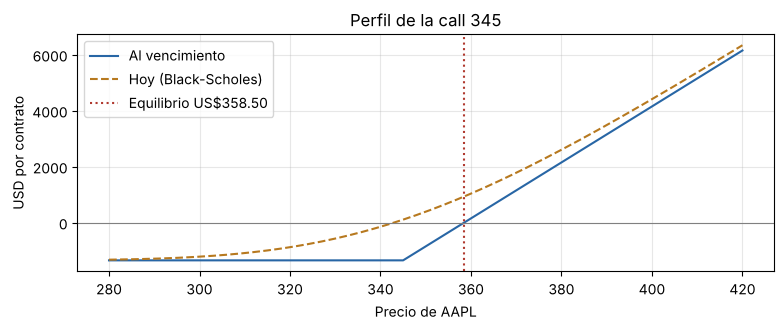

In [9]:
ST = np.linspace(280, 420, 141)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(ST, 100 * (np.maximum(ST - K, 0) - prima_pagada), color="#2866a5", label="Al vencimiento")
ax.plot(ST, [100 * (bs(s, K, r, q, sigma_garch, T) - prima_pagada) for s in ST], color="#b7791f", ls="--", label="Hoy (Black-Scholes)")
ax.axhline(0, color="gray", lw=.8); ax.axvline(K + prima_pagada, color="#b0392f", ls=":", label=f"Equilibrio US${K + prima_pagada:.2f}")
ax.set_xlabel("Precio de AAPL"); ax.set_ylabel("USD por contrato"); ax.set_title("Perfil de la call 345")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

## 6. Bono convertible: bono recto + opción, validación con Molson Coors y call spread

In [10]:
def precio_bono(c, y, T=6, m=2, F=1000):
    n = int(T * m); t = np.arange(1, n + 1)
    return np.sum(F * c / m / (1 + y / m) ** t) + F / (1 + y / m) ** n

def convertible(S, prima, rf, y, s, q=0.0, T=6, F=1000):
    Kc = S * (1 + prima); n = F / Kc
    opcion = bs(S, Kc, rf, q, s, T) * n
    cupon = brentq(lambda c: precio_bono(c, y, T) + opcion - F, -0.3, 0.3)
    return {"Precio de conversión": Kc, "Opción por bono": opcion, "Bono recto": precio_bono(cupon, y, T), "Cupón a la par": cupon}

molson = convertible(87.61, 0.25, 0.0446, 0.0575, 0.23)
V = R["conv"]
apple = convertible(S0, 0.30, V["rf"], V["y"], V["sigma"], q)
caso = dict(zip(molson.keys(), [109.51, 191.5, 808.5, 0.0193]))
pd.DataFrame([molson, caso, apple], index=["Molson Coors (modelo)", "Molson Coors (caso)", "Apple (proyecto)"]).style.format(
    {"Precio de conversión": "US${:.2f}", "Opción por bono": "US${:.2f}", "Bono recto": "US${:.2f}", "Cupón a la par": "{:.2%}"})

,Precio de conversión,Opción por bono,Bono recto,Cupón a la par
Molson Coors (modelo),US$109.51,US$191.52,US$808.48,1.93%
Molson Coors (caso),US$109.51,US$191.50,US$808.50,1.93%
Apple (proyecto),US$445.08,US$218.17,US$781.83,0.82%


In [11]:
def call_spread(S, p1, p2, rf, s, q, monto, T=6):
    K1, K2 = S * (1 + p1), S * (1 + p2); acc = monto / K1
    calls, warr = acc * bs(S, K1, rf, q, s, T), acc * bs(S, K2, rf, q, s, T)
    return {"Paga por las calls": calls / 1e6, "Cobra por los warrants": warr / 1e6, "Costo neto": (calls - warr) / 1e6,
            "Costo neto (% del principal)": 100 * (calls - warr) / monto}

m_cs = call_spread(87.61, 0.25, 0.60, 0.0446, 0.23, 0, 575e6)
print("Millones de USD (última columna en %)")
pd.DataFrame([m_cs, dict(zip(m_cs.keys(), [106.7, 57.0, 49.7, 8.6])), call_spread(S0, 0.30, 0.75, V["rf"], V["sigma"], q, 10e9)],
             index=["Molson Coors 25% → 60% (modelo)", "Molson Coors (caso)", "Apple 30% → 75%"]).round(1)

Millones de USD (última columna en %)


,Paga por las calls,Cobra por los warrants,Costo neto,Costo neto (% del principal)
Molson Coors 25% → 60% (modelo),110.1,68.9,41.2,7.2
Molson Coors (caso),106.7,57.0,49.7,8.6
Apple 30% → 75%,2181.7,1445.1,736.6,7.4


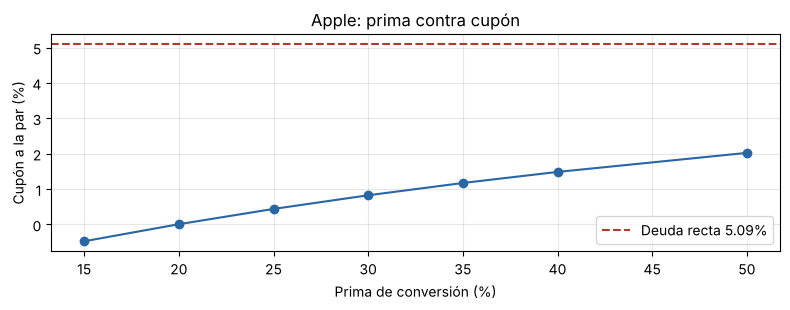

,Precio de conversión,Opción por bono,Bono recto,Cupón a la par
15%,US$393.73,US$284.65,US$715.35,-0.48%
20%,US$410.84,US$259.98,US$740.02,0.01%
25%,US$427.96,US$237.93,US$762.07,0.44%
30%,US$445.08,US$218.17,US$781.83,0.82%
35%,US$462.20,US$200.41,US$799.59,1.17%
40%,US$479.32,US$184.42,US$815.58,1.48%
50%,US$513.55,US$156.91,US$843.09,2.02%


In [12]:
primas = [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]
sens = pd.DataFrame([convertible(S0, p, V["rf"], V["y"], V["sigma"], q) for p in primas], index=[f"{p:.0%}" for p in primas])
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot([p * 100 for p in primas], sens["Cupón a la par"] * 100, "o-", color="#2866a5")
ax.axhline(V["y"] * 100, color="#b0392f", ls="--", label=f"Deuda recta {V['y']:.2%}")
ax.set_xlabel("Prima de conversión (%)"); ax.set_ylabel("Cupón a la par (%)"); ax.set_title("Apple: prima contra cupón")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()
sens.style.format({"Precio de conversión": "US${:.2f}", "Opción por bono": "US${:.2f}", "Bono recto": "US${:.2f}", "Cupón a la par": "{:.2%}"})

**Interpretación.** El método reproduce el caso Molson Coors (opción de US$191.5 y cupón de 1.93%) y da para Apple un cupón
de 0.82% con prima de 30%. Una prima mayor sube el cupón hacia el de la deuda recta; ninguna combinación es gratis: lo que
Apple deja de pagar en cupón lo entrega en opciones, y subir la prima efectiva con un call spread tiene un costo neto.